
⏱ Training Time: 0.30 seconds

Train Scores:
  MAE:  0.05575
  RMSE: 0.08814
  R²:   0.96912

Test Scores:
  MAE:  0.14811
  RMSE: 0.21999
  R²:   0.82028

📉 5-Fold Cross-Validation R² Scores:
  Fold 1: R² = 0.88148
  Fold 2: R² = 0.74660
  Fold 3: R² = 0.80871
  Fold 4: R² = 0.79494
  Fold 5: R² = 0.79918

Mean R²: 0.80618
Std Dev: 0.04336

🧪 Predicted Composite TC for input [1.05, 16, 15]: 0.9229


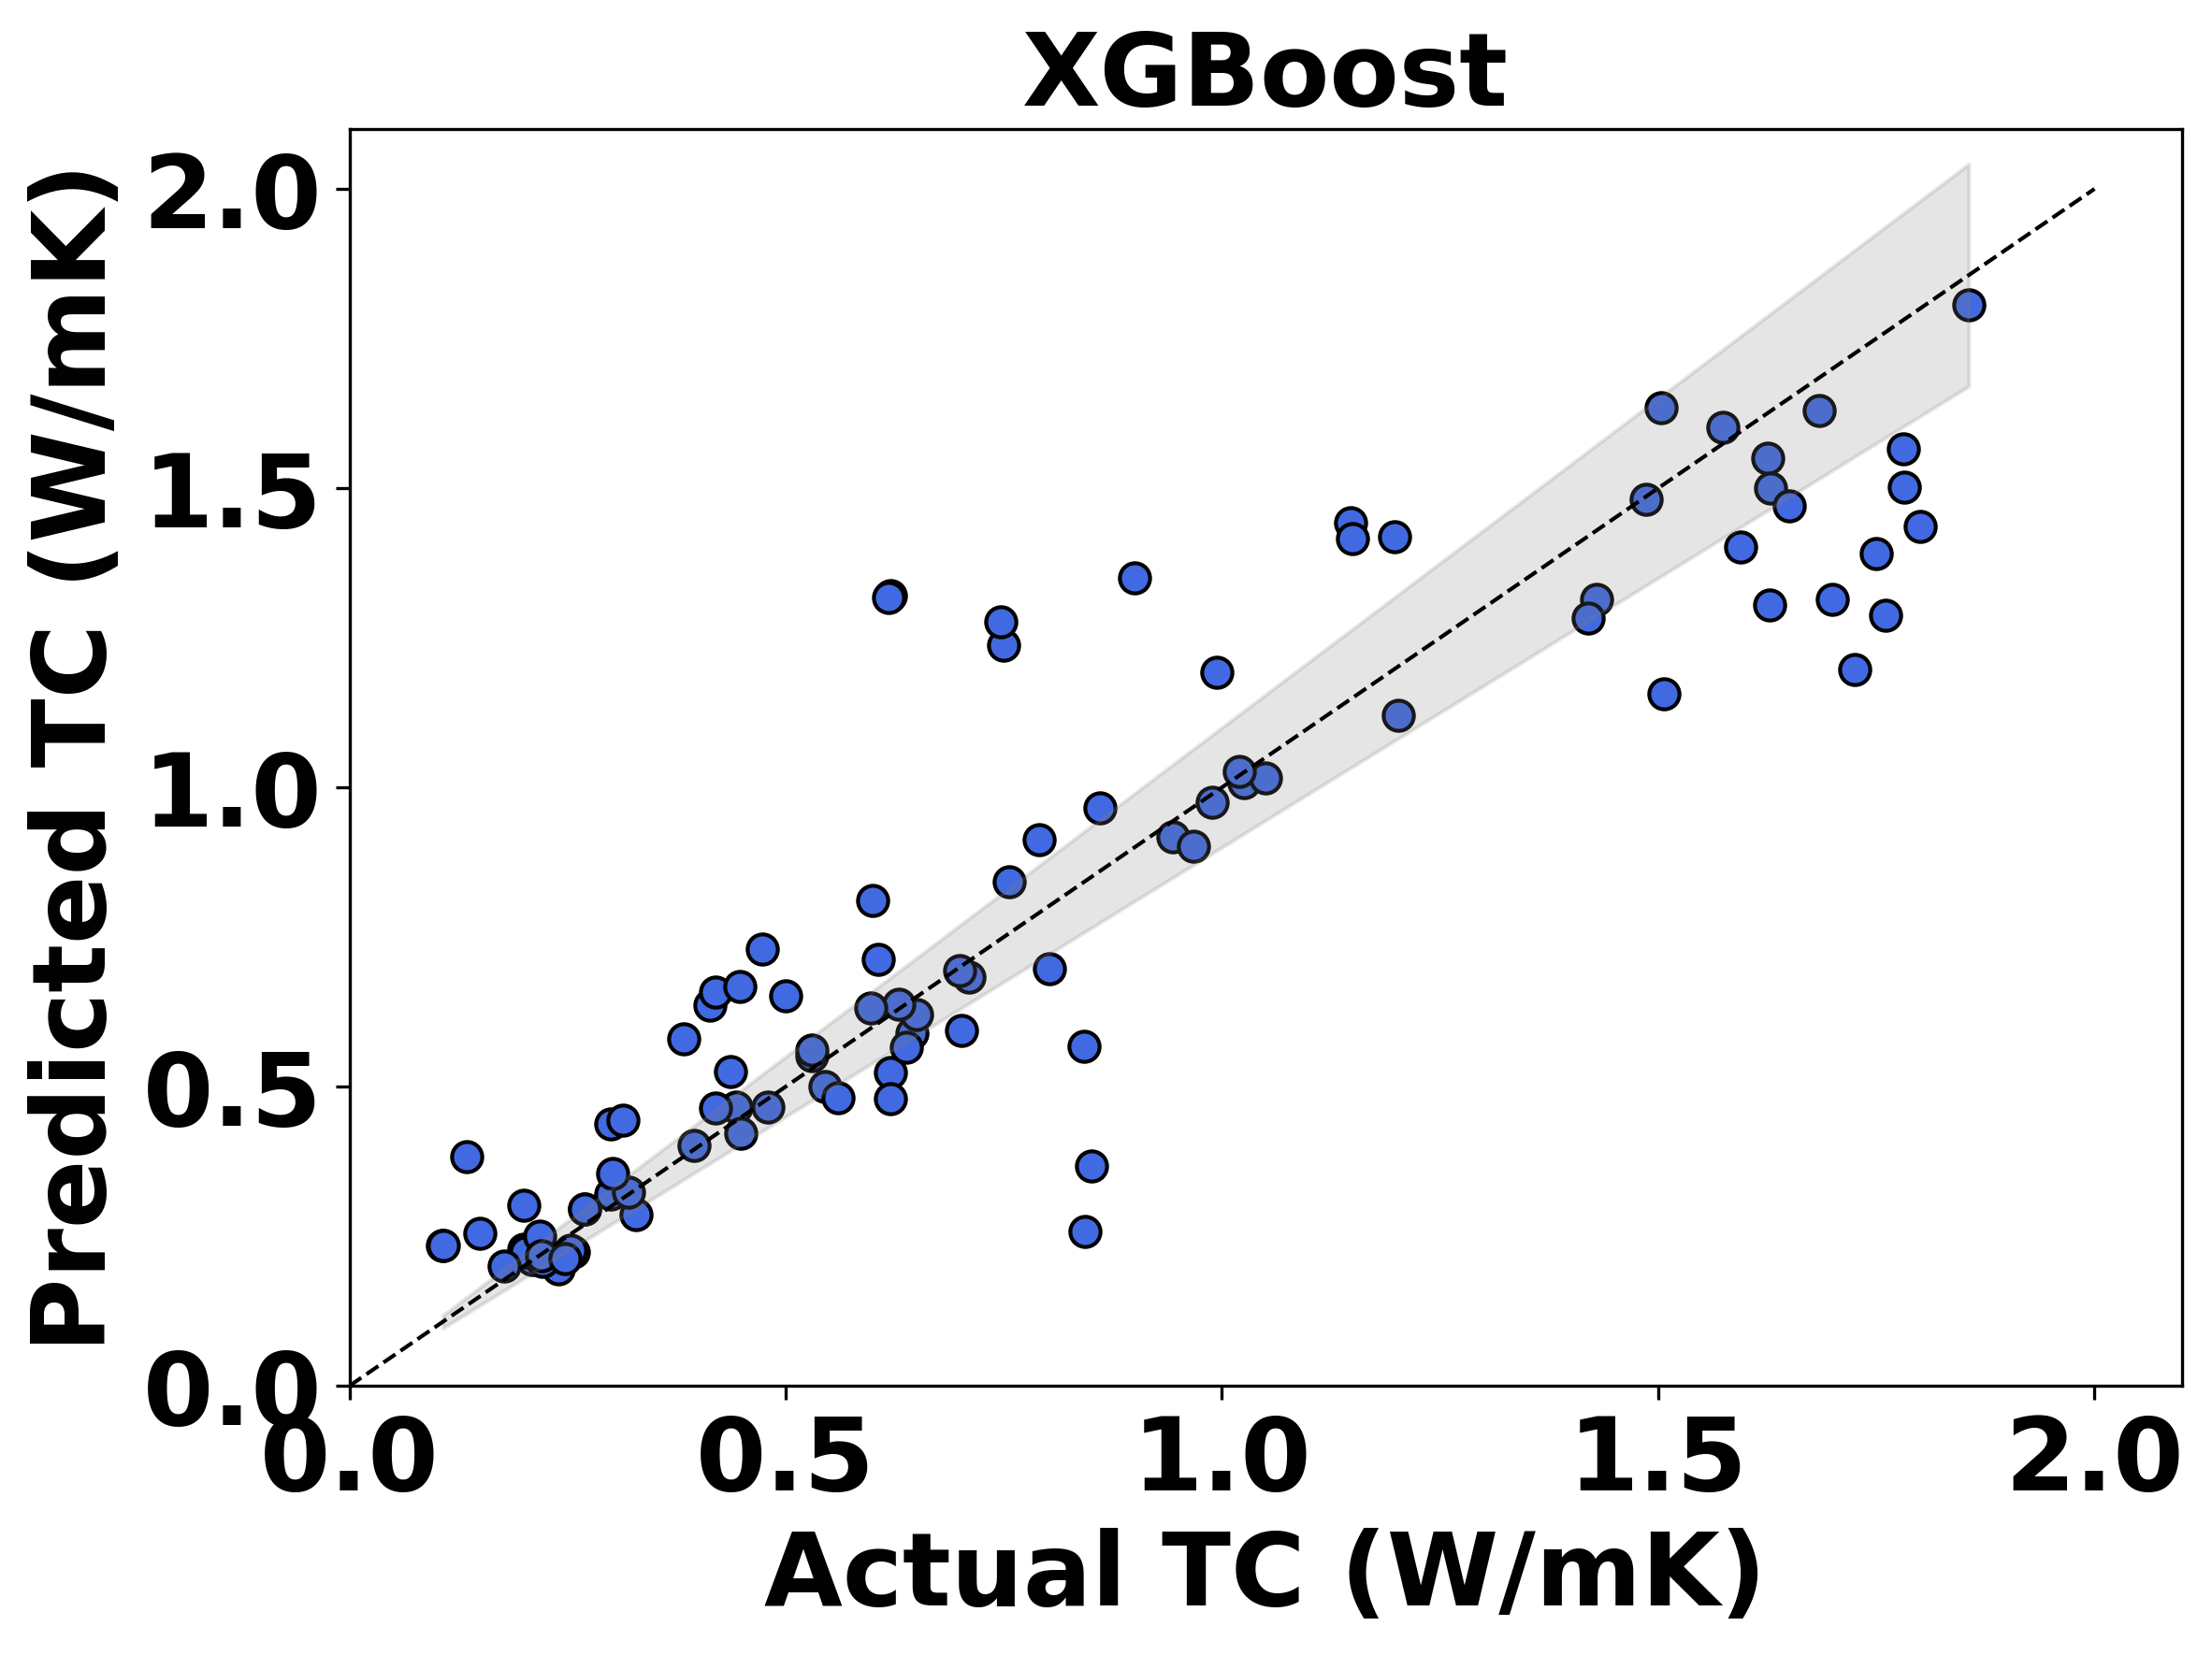

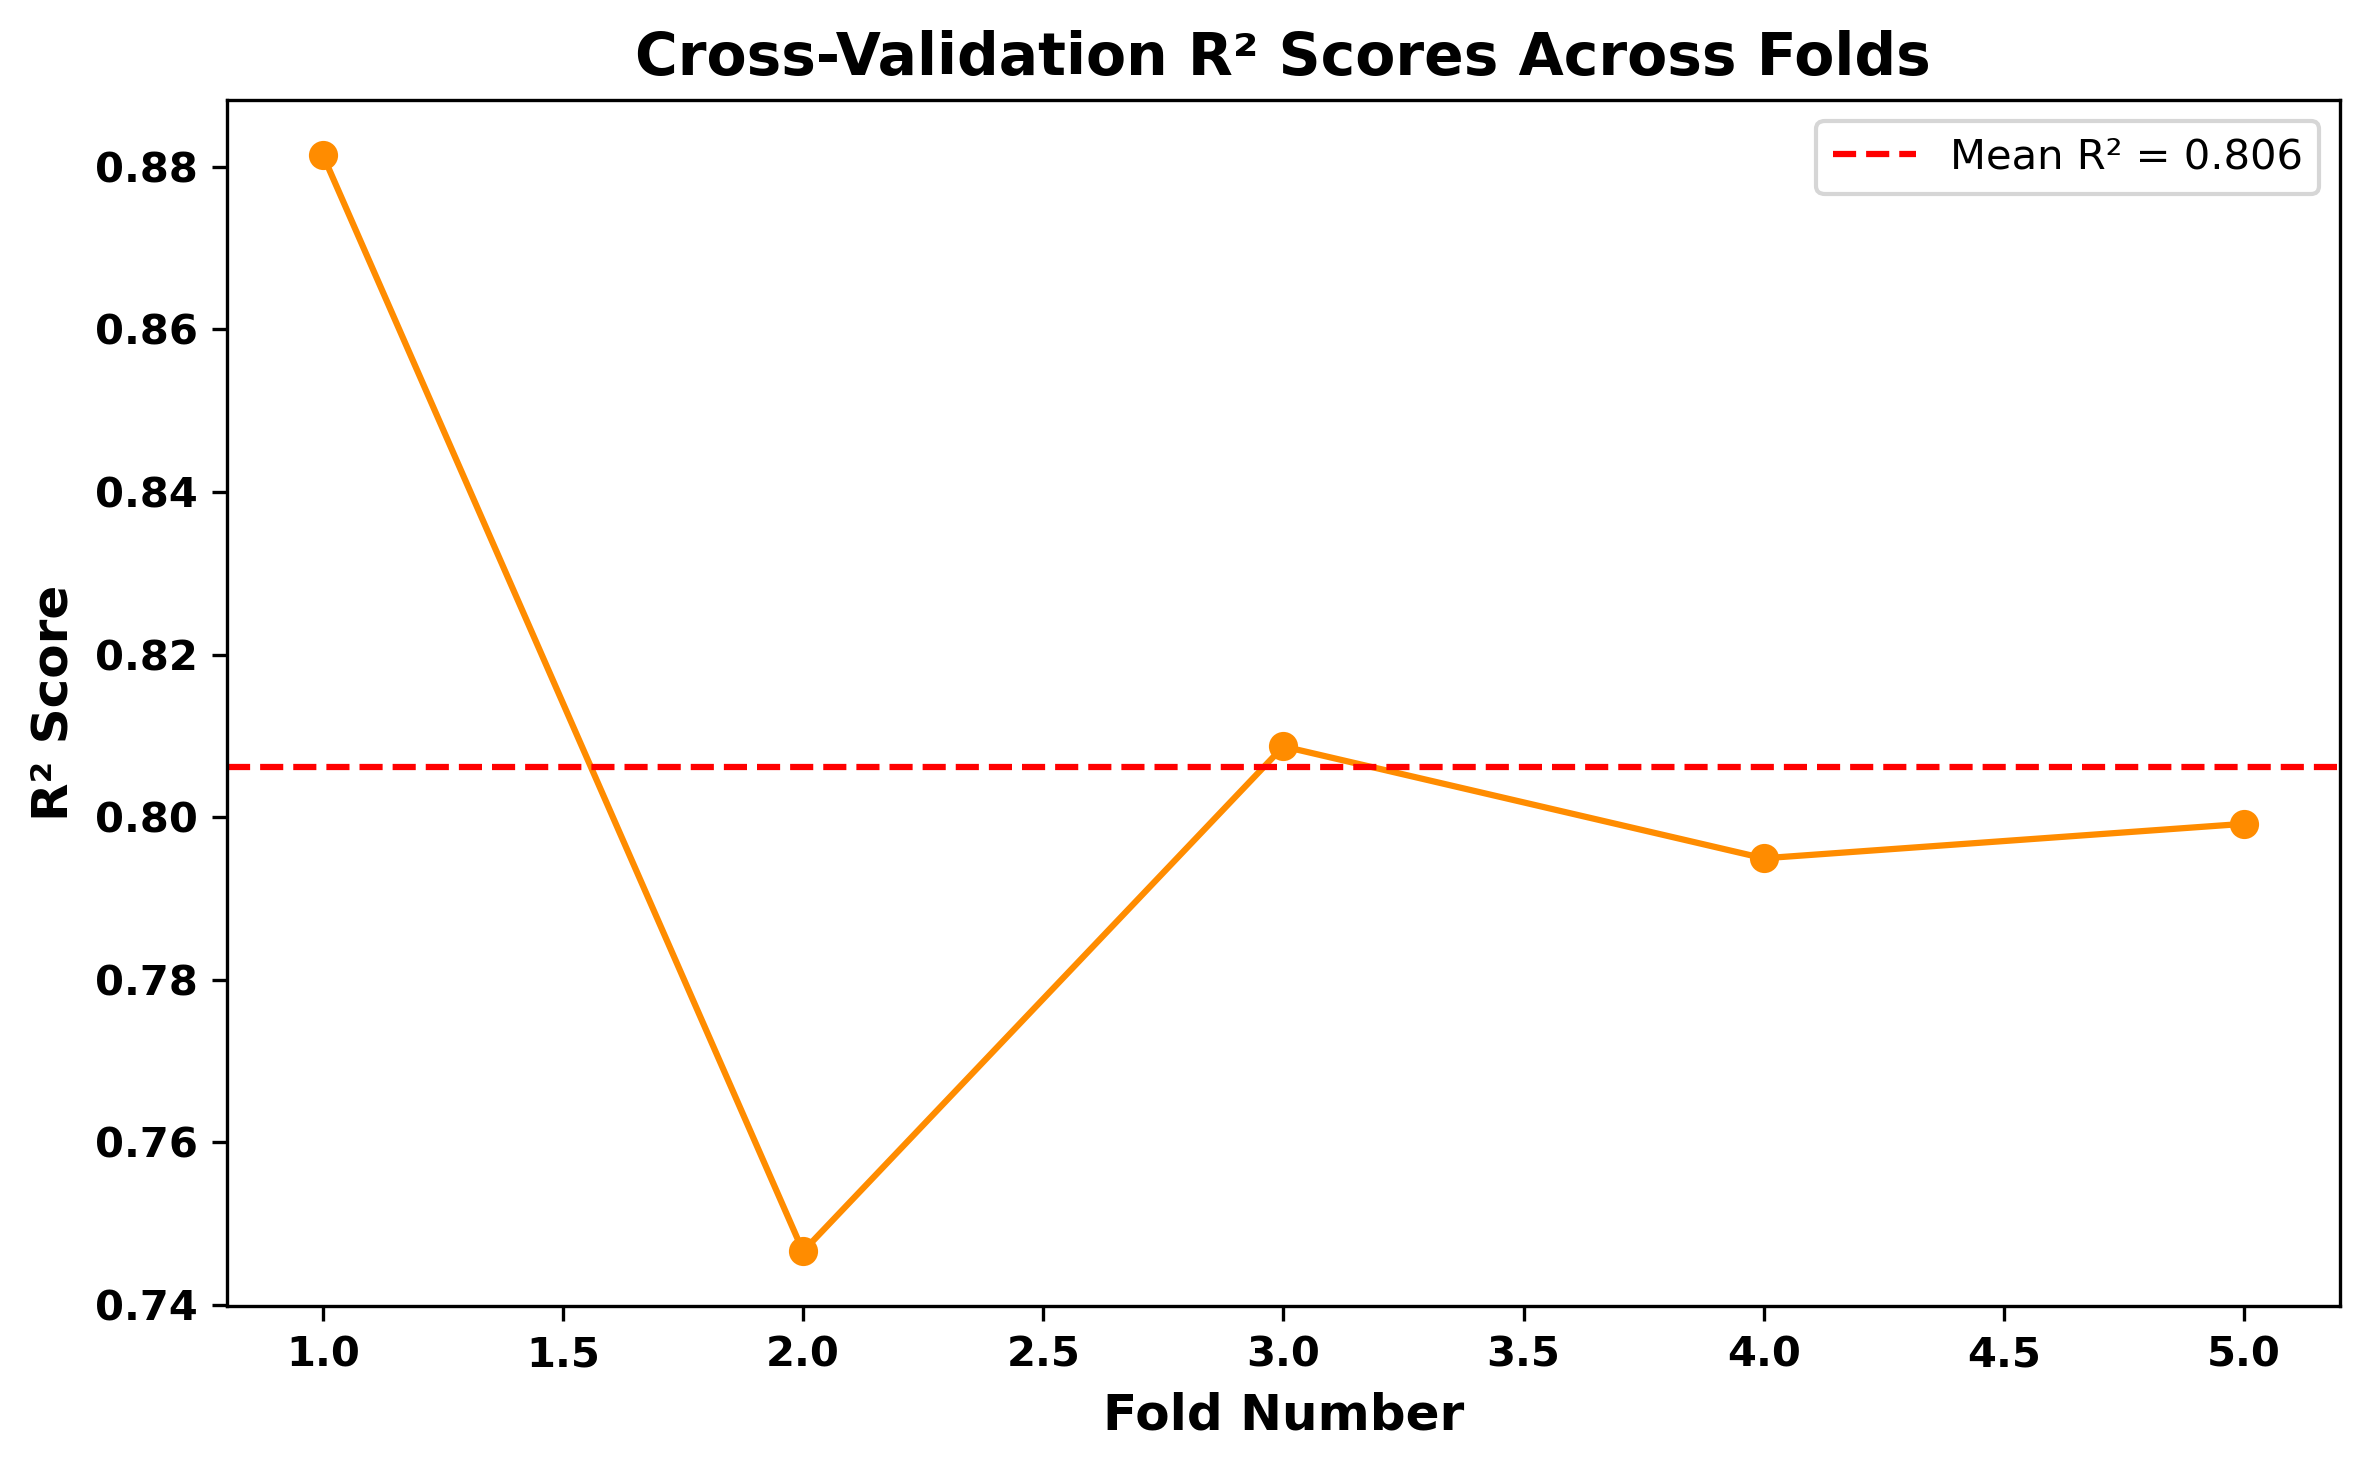

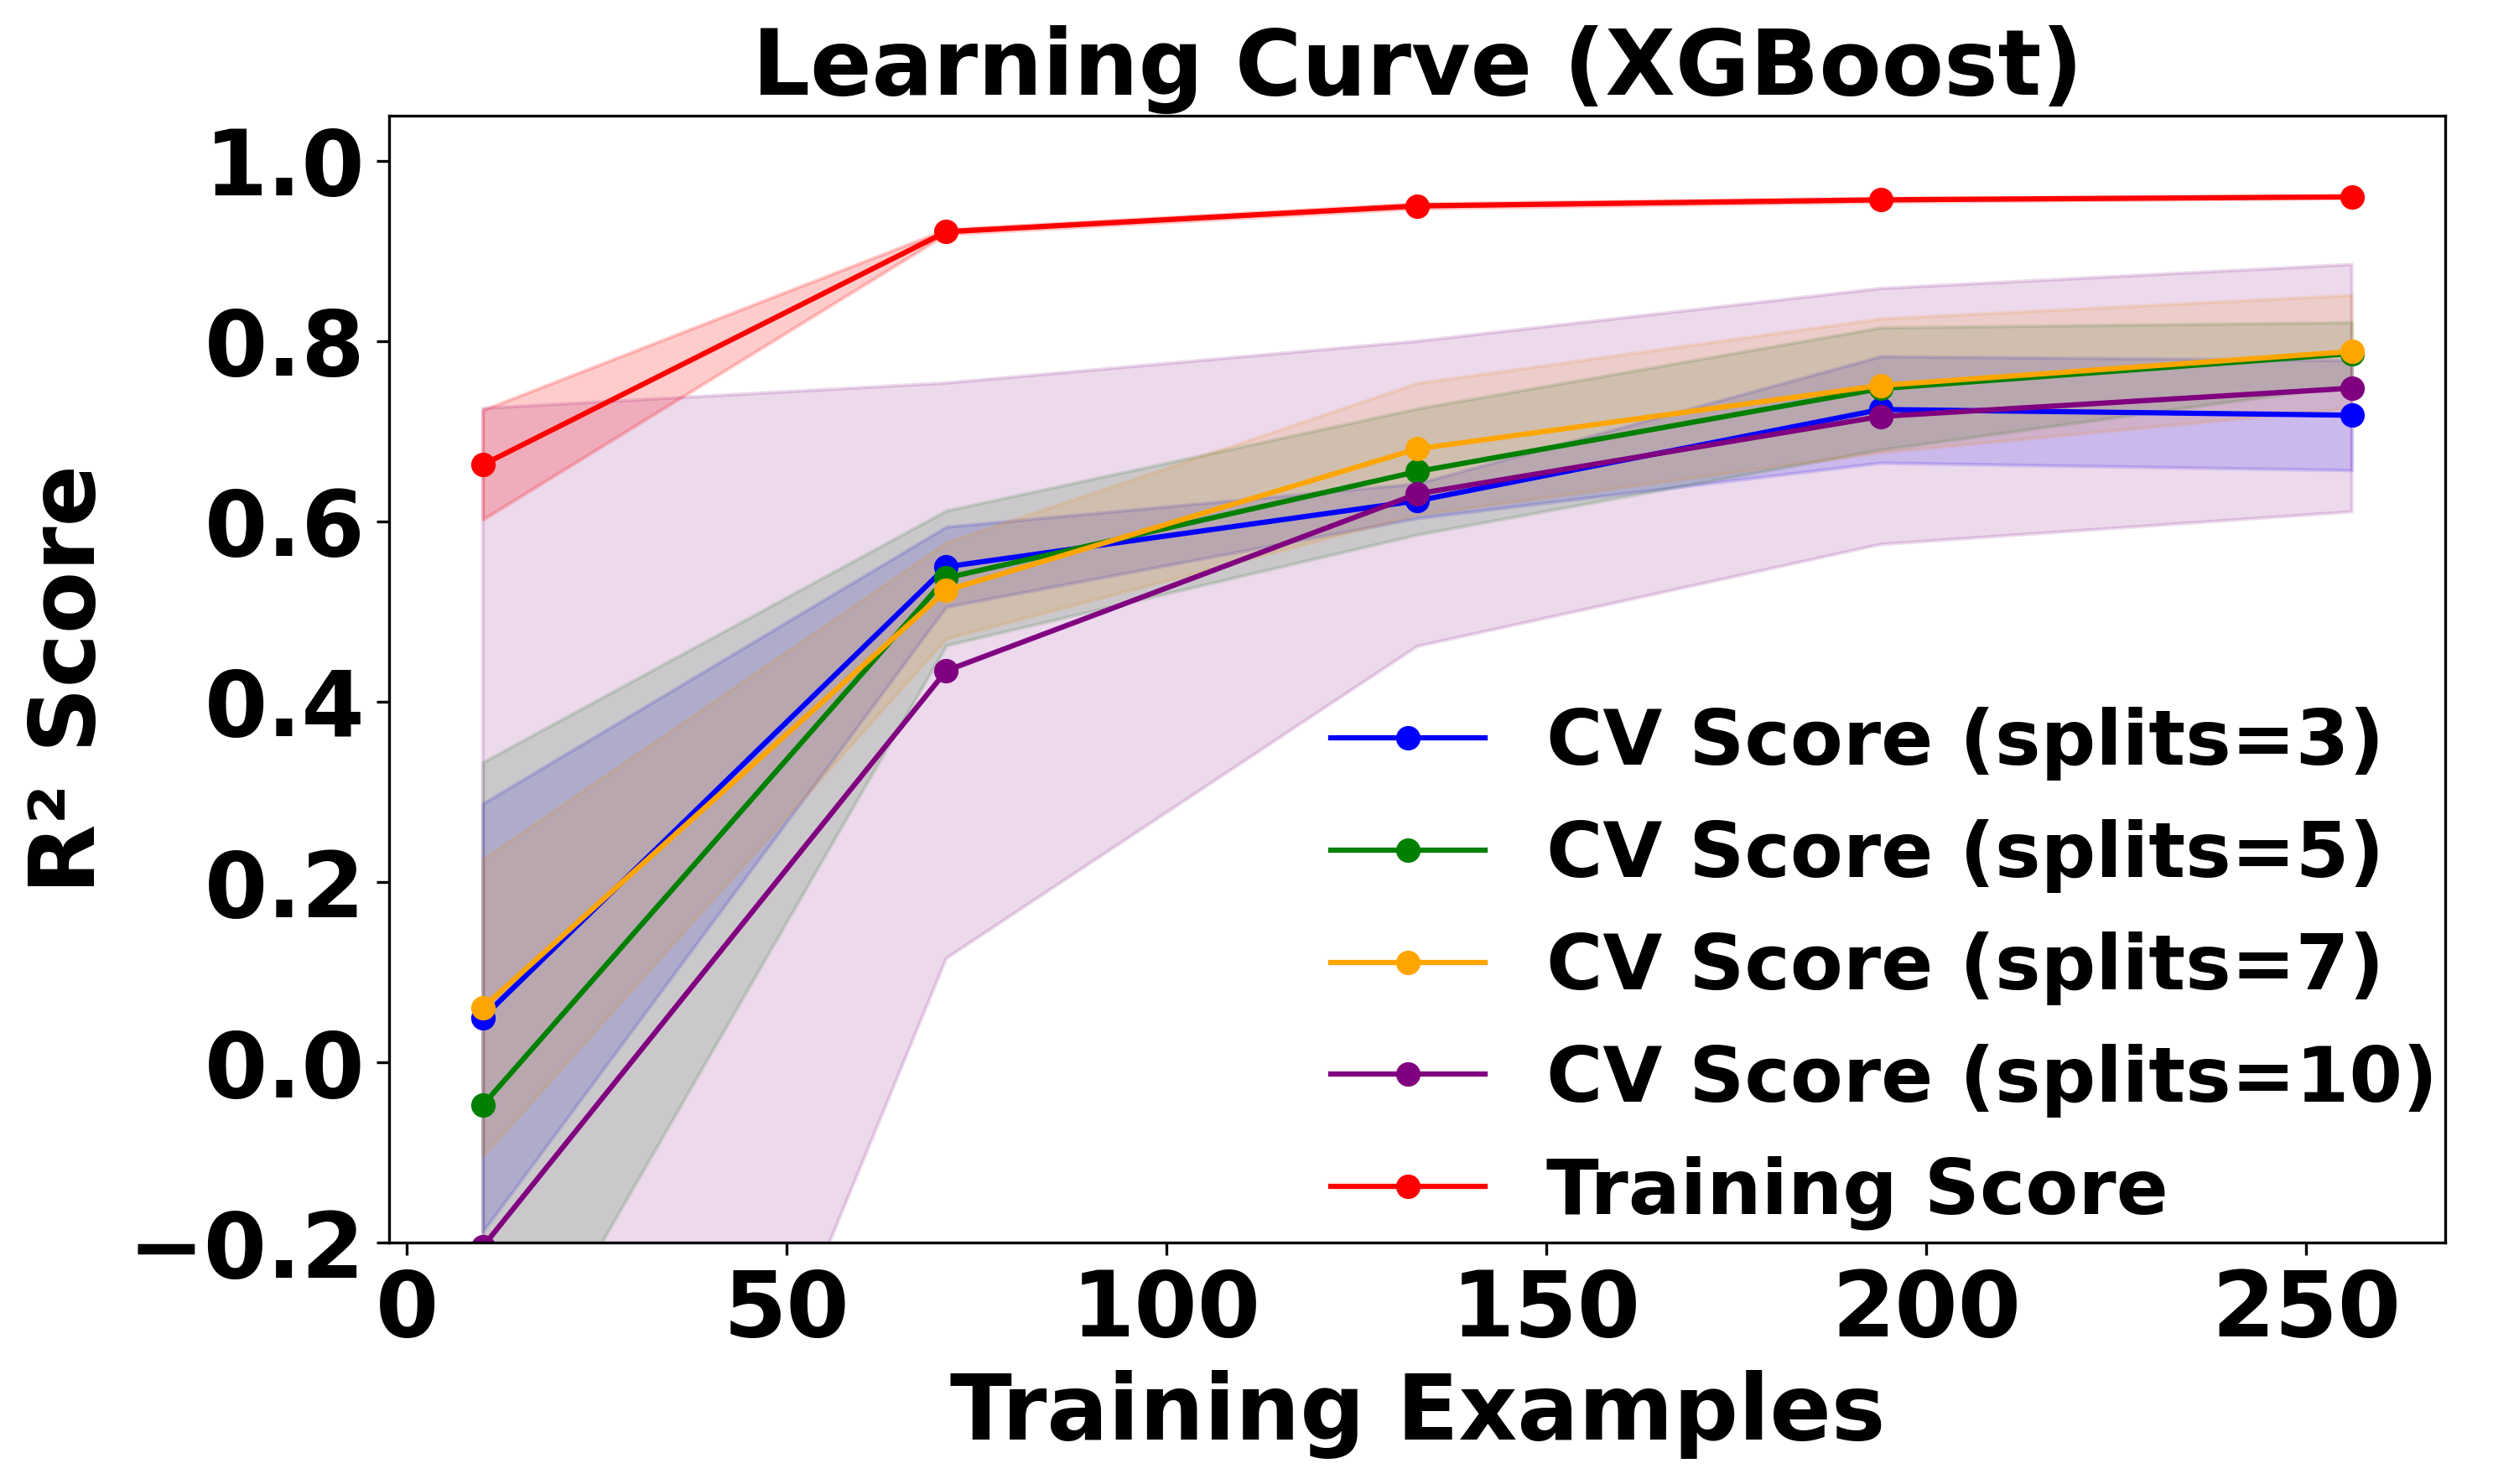

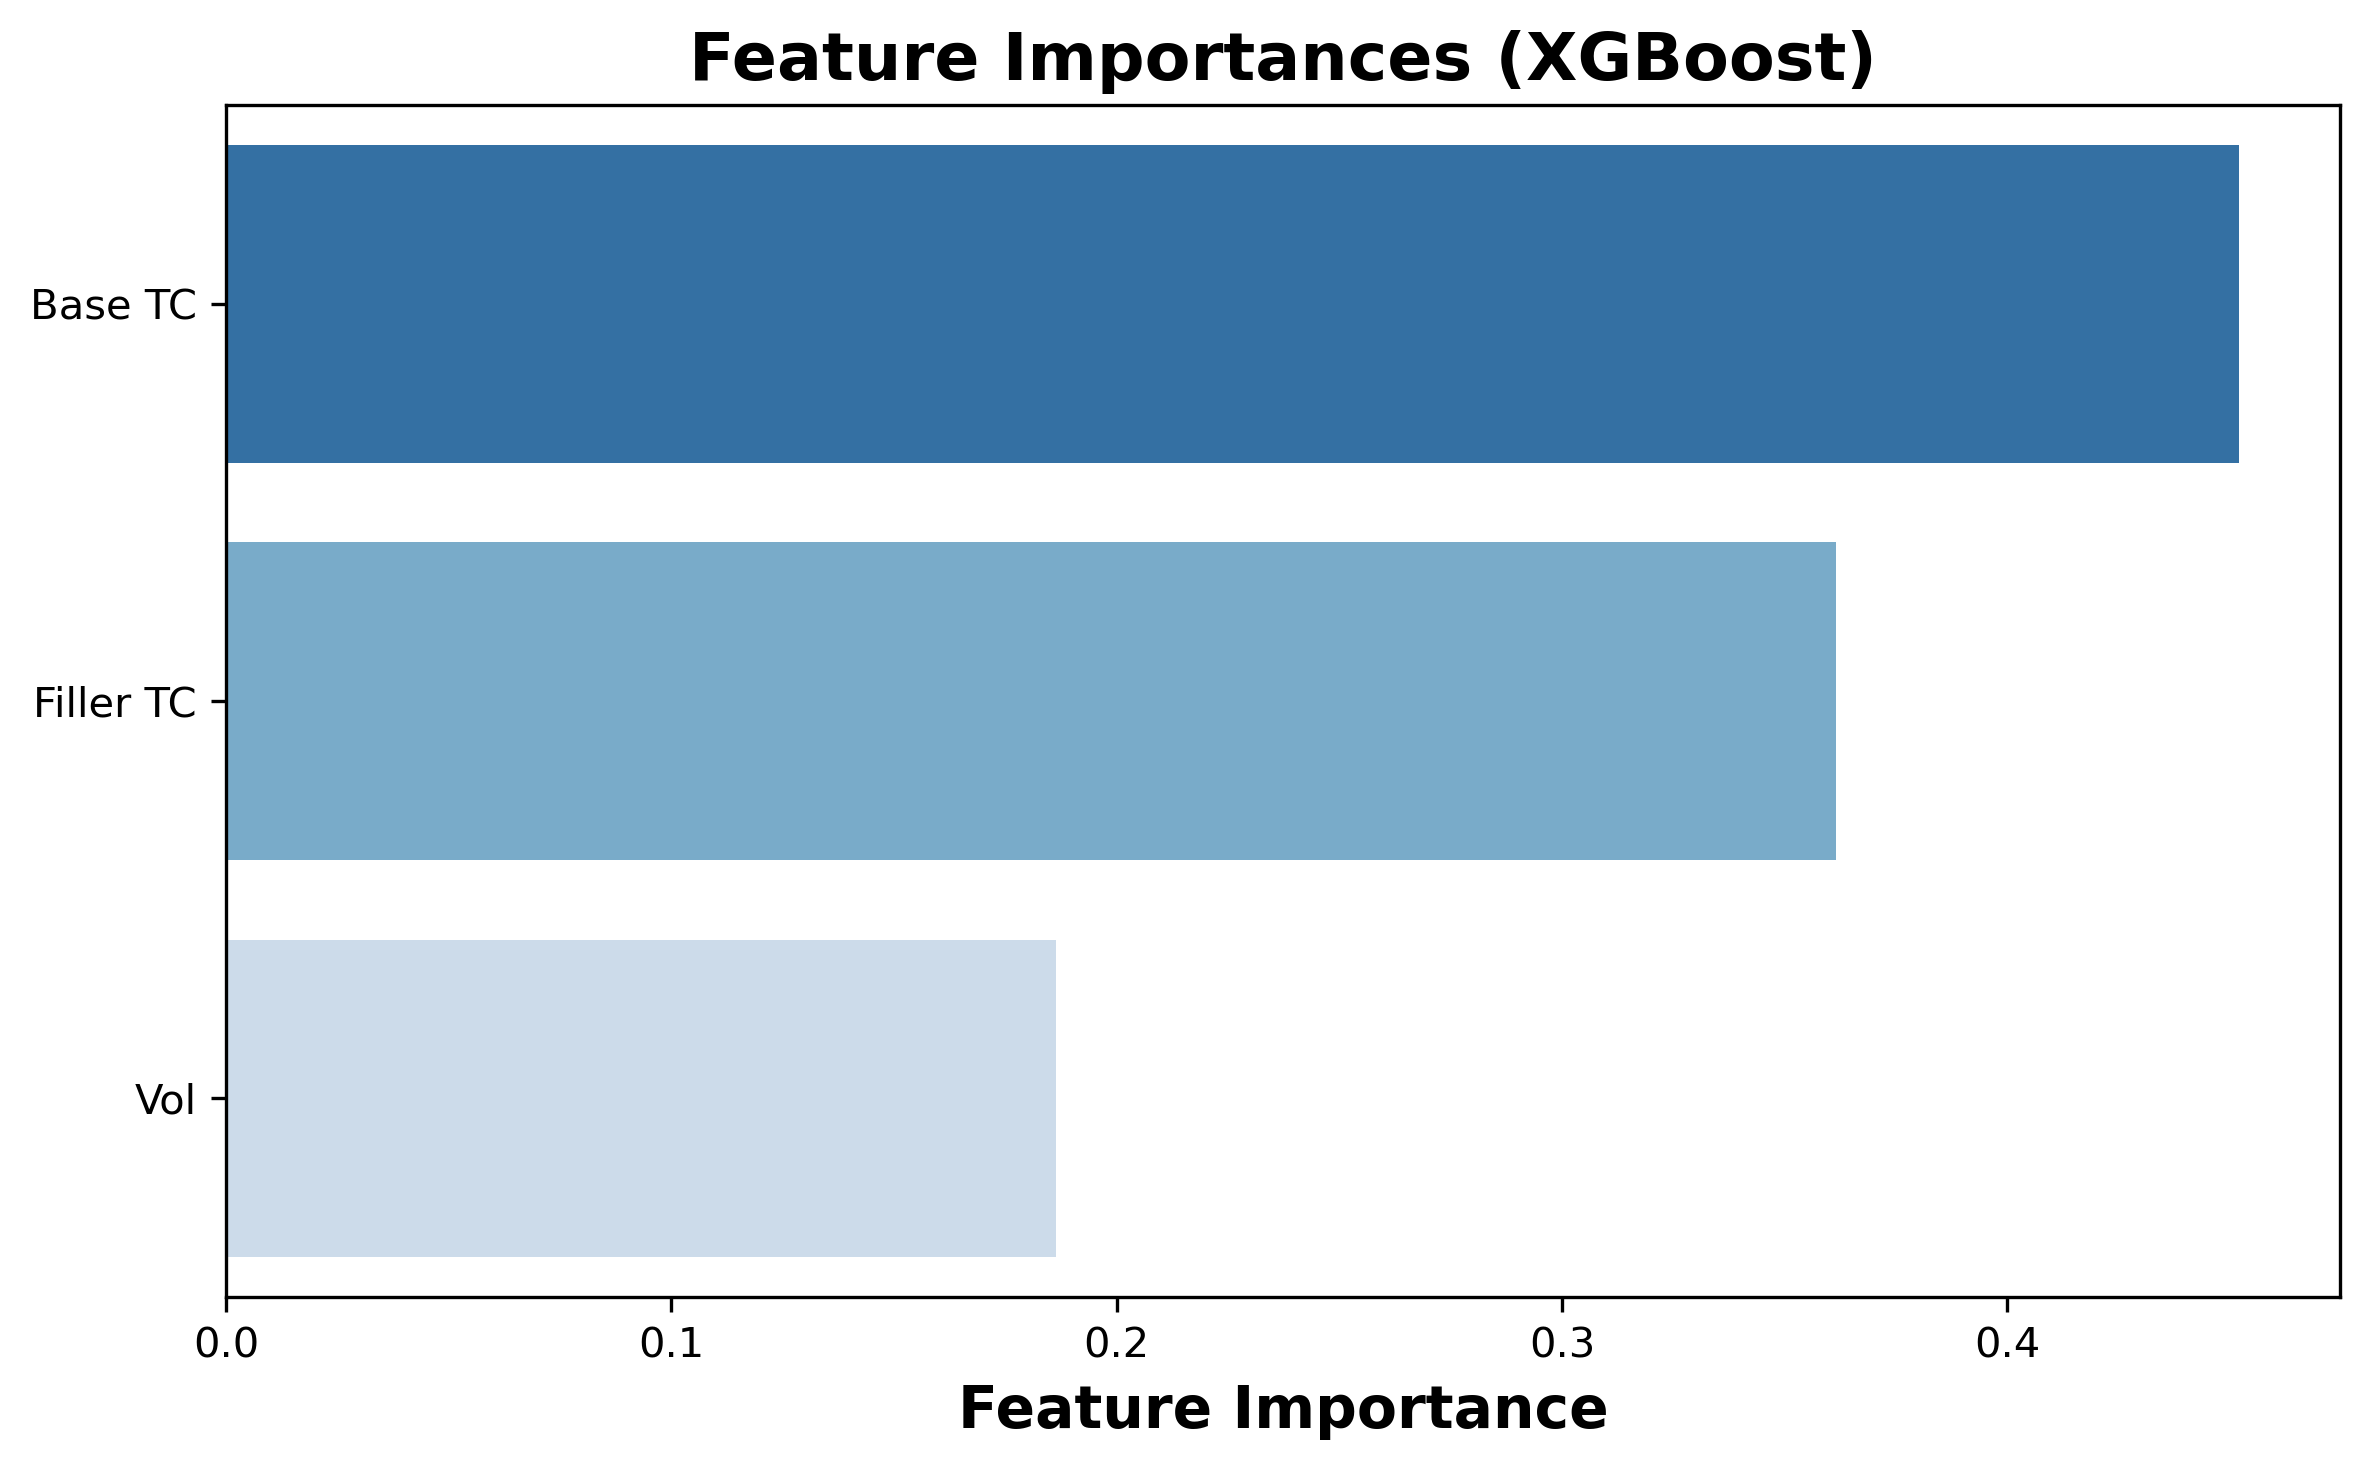

In [8]:
# 📦 Imports
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, KFold, learning_curve
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# 📂 Load Dataset
file_path = r'F:\Program Files (x86)\OneDrive\Desktop\ML edit 18\Room\Room_Temp_3x_Augmented_1Percent_Noise.xlsx'
df = pd.read_excel(file_path)

# 🧹 Features & Target
X = df.drop(columns=["Composite TC"])
y = df["Composite TC"]

# ✂️ Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ✅ Final XGBoost model with tuned hyperparameters
model = XGBRegressor(
    subsample=0.6,
    reg_lambda=1,
    reg_alpha=1,
    n_estimators=400,
    max_depth=8,
    learning_rate=0.1,
    gamma=0,
    colsample_bytree=1.0,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# 🚀 Train Model
start = time.time()
model.fit(X_train, y_train)
end = time.time()
print(f"\n⏱ Training Time: {end - start:.2f} seconds")

# 📈 Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# 📊 Evaluation Function
def print_scores(y_true, y_pred, label=""):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = mean_squared_error(y_true, y_pred, squared=False)
    r2 = r2_score(y_true, y_pred)
    print(f"\n{label} Scores:")
    print(f"  MAE:  {mae:.5f}")
    print(f"  RMSE: {rmse:.5f}")
    print(f"  R²:   {r2:.5f}")

# 🧾 Final Evaluation
print_scores(y_train, y_train_pred, "Train")
print_scores(y_test, y_test_pred, "Test")

# 🔁 5-Fold Cross-validation
cv = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='r2', n_jobs=-1)
print("\n📉 5-Fold Cross-Validation R² Scores:")
for i, score in enumerate(cv_scores, 1):
    print(f"  Fold {i}: R² = {score:.5f}")
print(f"\nMean R²: {cv_scores.mean():.5f}")
print(f"Std Dev: {cv_scores.std():.5f}")

# 🔍 Manual Prediction
manual_input = [[1.05, 16, 15]]
predicted_tc = model.predict(manual_input)
print(f"\n🧪 Predicted Composite TC for input {manual_input[0]}: {predicted_tc[0]:.4f}")

# 🖼️ Scatter Plot with ±10% Band
y_true = y_test.values
y_pred = y_test_pred
lower = y_true * 0.90
upper = y_true * 1.10
sorted_idx = np.argsort(y_true)

plt.figure(figsize=(8, 6), dpi=300)
plt.scatter(y_true, y_pred, color='royalblue', s=60, edgecolor='black')
plt.fill_between(np.sort(y_true), lower[sorted_idx], upper[sorted_idx], color='gray', alpha=0.2)
plt.plot([0, 2.0], [0, 2.0], 'k--', lw=1)
plt.xlim(0, 2.10)
plt.ylim(0, 2.10)
plt.xlabel('Actual TC (W/mK)', fontsize=26, fontweight='bold')
plt.ylabel('Predicted TC (W/mK)', fontsize=26, fontweight='bold')
plt.title('XGBoost', fontsize=26, fontweight='bold')
plt.locator_params(axis='x', nbins=6)
plt.locator_params(axis='y', nbins=6)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# 📈 Line Plot of CV Scores
plt.figure(figsize=(8, 5), dpi=300)
plt.plot(range(1, len(cv_scores)+1), cv_scores, marker='o', linestyle='-', color='darkorange')
plt.axhline(y=cv_scores.mean(), color='red', linestyle='--', label=f'Mean R² = {cv_scores.mean():.3f}')
plt.title('Cross-Validation R² Scores Across Folds', fontsize=14, fontweight='bold')
plt.xlabel('Fold Number', fontsize=12, fontweight='bold')
plt.ylabel('R² Score', fontsize=12, fontweight='bold')
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')
plt.grid(False)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

# 📚 Learning Curve
splits_list = [3, 5, 7, 10]
colors = ['blue', 'green', 'orange', 'purple']
min_allowed_size = min([int(len(X_train) * ((s - 1) / s)) for s in splits_list])
train_sizes_fixed = np.linspace(10, min_allowed_size, 5, dtype=int)

plt.figure(figsize=(10, 6), dpi=300)
for split, color in zip(splits_list, colors):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        train_sizes=train_sizes_fixed,
        cv=KFold(n_splits=split, shuffle=True, random_state=42),
        scoring='r2',
        n_jobs=-1
    )
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    plt.plot(train_sizes, val_mean, marker='o', color=color, label=f'CV Score (splits={split})')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, color=color, alpha=0.15)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
plt.plot(train_sizes, train_mean, marker='o', color='red', label='Training Score')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, color='red', alpha=0.2)

plt.title('Learning Curve (XGBoost)', fontsize=26, fontweight='bold')
plt.xlabel('Training Examples', fontsize=26, fontweight='bold')
plt.ylabel('R² Score', fontsize=26, fontweight='bold')
plt.legend(loc='lower right', bbox_to_anchor=(1.03, -0.05), prop={'weight': 'bold', 'size': 22}, frameon=False)
plt.xticks(fontsize=26, fontweight='bold')
plt.yticks(fontsize=26, fontweight='bold')
plt.ylim(-0.2, 1.05)
plt.grid(False)
plt.tight_layout()
plt.show()

# 🔍 Feature Importance
importances = model.feature_importances_
feature_names = X.columns
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 5), dpi=300)
sns.barplot(x=importances[indices], y=feature_names[indices], palette="Blues_r")
plt.xlabel('Feature Importance', fontsize=14, fontweight='bold')
plt.title('Feature Importances (XGBoost)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()
